 # O problema foi utilizar GARCH para estimar volatilidade ou utilizar uma regra de ponderação que penaliza excessivamente as ações de maior risco?

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import sys

# Localizar a raiz do repositório
raiz = Path.cwd().resolve()

while not (raiz / "baseDeDados" / "economatica-3.xlsx").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Repositório não encontrado.")
    raiz = raiz.parent

# Importar funções existentes
pasta_funcoes = raiz / "notebooks e resultados" / "momentum com garch"

sys.path.insert(0, str(pasta_funcoes))

from initial_test import preparar_dados, criar_pesos_vol, baixar_cdi
from funcoes_momentum import (
    criar_top_n,
    criar_pesos,
    backtest,
    calcular_metricas
)

# Caminhos
arquivo_precos = raiz / "baseDeDados" / "economatica-3.xlsx"

arquivo_cdi = raiz / "baseDeDados" / "cdi_sgs12.csv"

arquivo_cache = (
    raiz / "notebooks e resultados"
    / "modelos volatilidade"
    / "cache_vol_modelos.pkl"
)

print("Base encontrada:", arquivo_precos.exists())
print("CDI encontrado:", arquivo_cdi.exists())
print("Cache GJR encontrado:", arquivo_cache.exists())

Base encontrada: True
CDI encontrado: True
Cache GJR encontrado: True


In [2]:
precos, retornos, momentos, datas = preparar_dados(
    path=arquivo_precos,
    inicio_hist="2015-01-01",
    inicio_bt="2017-01-01",
    fim="2021-12-31"
)

carteira_top5 = criar_top_n(
    momentos["12-1"],
    n=5
)

with open(arquivo_cache, "rb") as f:
    cache = pickle.load(f)

assinatura = (
    tuple(retornos.columns),
    str(retornos.index[0]),
    str(retornos.index[-1]),
    len(datas),
    str(datas[0]),
    str(datas[-1]),
    21,
    252
)

if cache.get("fingerprint") != assinatura:
    raise ValueError("Cache incompatível com os dados atuais.")

sigma_gjr = cache["specs"][("gjr", 756)][0]

print("Ações disponíveis:", len(retornos.columns))
print("Rebalanceamentos:", len(carteira_top5))
print("Dimensão das previsões GJR:", sigma_gjr.shape)

display(carteira_top5.head())
display(sigma_gjr.head())

[dados] 30 ativos | 2015-01-02 a 2021-12-30 | 60 datas de sinal
Ações disponíveis: 30
Rebalanceamentos: 60
Dimensão das previsões GJR: (60, 30)


,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4
2017-02-24,MGLU3,USIM5,GOAU4,GGBR4,PETR4
2017-03-31,MGLU3,USIM5,GOAU4,SANB3,VALE3
2017-04-28,MGLU3,PRIO3,GOAU4,SANB3,USIM5
2017-05-31,MGLU3,PRIO3,USIM5,GOAU4,BBAS3


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2017-01-31,0.012064,0.019735,0.021511,0.031483,0.031294,NaN,0.035412,0.023942,0.021199,0.013997,...,0.027482,0.051932,0.016447,0.032569,0.022520,0.037651,0.016942,0.042789,0.036692,0.018009
2017-02-24,0.011794,0.019404,0.020786,0.027739,0.030821,NaN,0.032286,0.021299,0.020978,0.013498,...,0.023465,0.050042,0.019012,0.030281,0.022726,0.036884,0.016227,0.035618,0.037911,0.017317
2017-03-31,0.012132,0.019810,0.019724,0.027010,0.022564,NaN,0.031881,0.020730,0.020909,0.013061,...,0.029370,0.054635,0.019152,0.032659,0.021655,0.039785,0.016926,0.040960,0.035987,0.016520
2017-04-28,0.011219,0.019621,0.020762,0.027339,0.022048,NaN,0.032820,0.021475,0.020846,0.012599,...,0.026449,0.049539,0.017859,0.032517,0.022592,0.040897,0.017597,0.038962,0.036458,0.015719
2017-05-31,0.013372,0.020635,0.021418,0.031962,0.020591,NaN,0.033004,0.027598,0.021384,0.012679,...,0.044347,0.050258,0.017967,0.032978,0.022877,0.042744,0.018949,0.044181,0.034927,0.019530


In [5]:
def criar_pesos_alpha(carteira, sigma, ativos, alpha):

    pesos = pd.DataFrame(0.0, index=carteira.index, columns=ativos)

    for data, linha in carteira.iterrows():

        selecionados = linha.dropna().tolist()

        if not selecionados:
            continue

        if alpha == 0:
            valores = pd.Series(1.0, index=selecionados)

        else:
            vol = sigma.loc[data, selecionados].astype(float)

            vol = vol.replace([np.inf, -np.inf], np.nan)
            vol = vol.where(vol > 0)

            if vol.notna().any():
                vol = vol.fillna(vol.median())
                valores = vol ** (-alpha)

            else:
                valores = pd.Series(1.0, index=selecionados)

        pesos.loc[data, selecionados] = valores / valores.sum()

    return pesos


alphas = [0, 0.25, 0.5, 1, 2]

carteiras_alpha = {
    alpha: criar_pesos_alpha(
        carteira_top5,
        sigma_gjr,
        retornos.columns,
        alpha
    )
    for alpha in alphas
}

for alpha, pesos in carteiras_alpha.items():
    print(
        f"Alpha = {alpha}:",
        "soma média dos pesos =",
        round(pesos.sum(axis=1).mean(), 6)
    )


# Comparação com as funções originais

pesos_iguais_originais = criar_pesos(
    carteira_top5, retornos.columns
)

pesos_gjr_original = criar_pesos_vol(
    carteira_top5, sigma_gjr, retornos.columns
)

erro_iguais = (
    carteiras_alpha[0] - pesos_iguais_originais
).abs().to_numpy().max()

erro_gjr = (
    carteiras_alpha[1] - pesos_gjr_original
).abs().to_numpy().max()

print("\nDiferença máxima para pesos iguais:", erro_iguais)
print("Diferença máxima para GJR original:", erro_gjr)

Alpha = 0: soma média dos pesos = 1.0
Alpha = 0.25: soma média dos pesos = 1.0
Alpha = 0.5: soma média dos pesos = 1.0
Alpha = 1: soma média dos pesos = 1.0
Alpha = 2: soma média dos pesos = 1.0

Diferença máxima para pesos iguais: 0.0
Diferença máxima para GJR original: 0.0


In [6]:
from funcoes_momentum import aplicar_custos

# Recuperar o CDI diário
cdi_diario = baixar_cdi(
    "2017-01-01",
    "2021-12-31",
    cache=str(arquivo_cdi)
)

if cdi_diario is None:
    raise ValueError("CDI indisponível. Verifique o arquivo de cache.")

# Executar um backtest para cada alpha
resultados_alpha = {}

for alpha, pesos in carteiras_alpha.items():

    resultados_alpha[alpha] = backtest(
        pesos,
        retornos,
        inicio="2017-01-01",
        fim="2021-12-31"
    )

# Separação por períodos
periodos = {
    "Treinamento (2017-2020)": ("2017-01-01", "2020-12-31"),
    "Validação (2021)": ("2021-01-01", "2021-12-31")
}

# Calcular métricas com custos
tabelas_alpha = {}

for periodo, (inicio, fim) in periodos.items():

    linhas = []

    for alpha, resultado in resultados_alpha.items():

        metricas = calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001,
            cdi=cdi_diario
        )

        metricas["Alpha"] = alpha
        linhas.append(metricas)

    tabela = pd.DataFrame(linhas).set_index("Alpha")

    tabelas_alpha[periodo] = tabela

    print(f"\n{periodo}")
    display(tabela.round(3))


Treinamento (2017-2020)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Alpha,,,,,
0.00,48.951,36.387,1.115,-51.292,6.034
0.25,46.088,35.597,1.077,-49.842,6.234
0.50,43.334,34.921,1.036,-48.460,6.484
1.00,38.234,33.885,0.950,-45.915,7.101
2.00,30.083,32.798,0.784,-41.675,8.322



Validação (2021)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Alpha,,,,,
0.00,24.656,33.602,0.695,-23.028,5.746
0.25,24.081,33.492,0.682,-23.224,5.899
0.50,23.479,33.396,0.669,-23.410,6.082
1.00,22.197,33.244,0.639,-23.756,6.567
2.00,19.424,33.082,0.571,-24.343,7.784


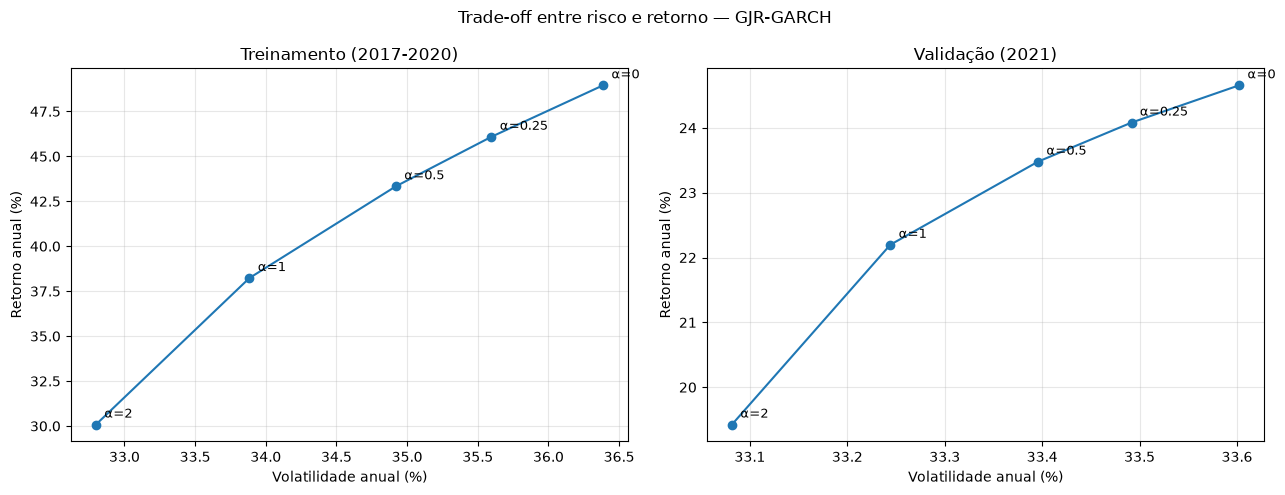

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (periodo, tabela) in zip(axes, tabelas_alpha.items()):

    x = tabela["Volatilidade (%)"]
    y = tabela["Retorno anual (%)"]

    ax.plot(x, y, marker="o", linewidth=1.5)

    for alpha in tabela.index:
        ax.annotate(
            f"α={alpha:g}",
            (x.loc[alpha], y.loc[alpha]),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=9
        )

    ax.set_title(periodo)
    ax.set_xlabel("Volatilidade anual (%)")
    ax.set_ylabel("Retorno anual (%)")
    ax.grid(True, alpha=0.3)

plt.suptitle("Trade-off entre risco e retorno — GJR-GARCH")
plt.tight_layout()
plt.show()

Ranking,1,2,3,4,5
Alpha,,,,,
0.00,20.00,20.00,20.00,20.00,20.00
0.25,18.78,19.36,20.18,20.57,21.12
0.50,17.61,18.68,20.35,21.11,22.25
1.00,15.52,17.25,20.66,22.07,24.51
2.00,12.31,14.49,21.10,23.47,28.64


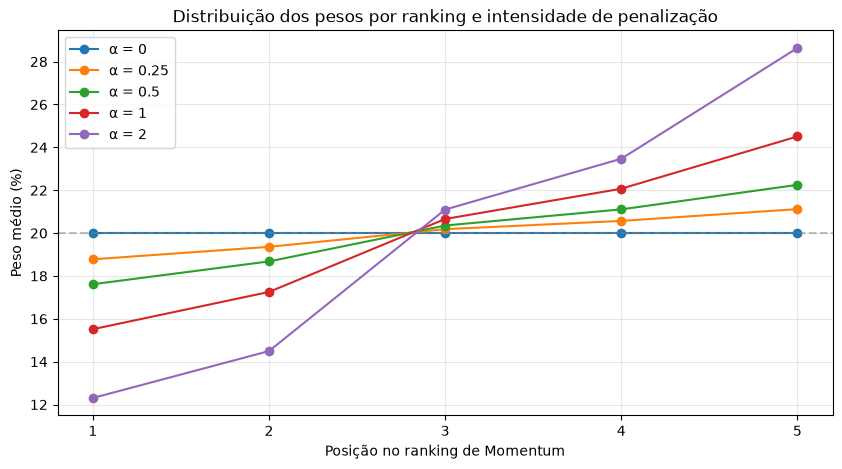

In [8]:
linhas = []

for alpha, pesos in carteiras_alpha.items():

    for data, ranking in carteira_top5.iterrows():

        for posicao, ativo in enumerate(ranking.dropna(), start=1):

            linhas.append({
                "Alpha": alpha,
                "Ranking": posicao,
                "Peso (%)": pesos.loc[data, ativo] * 100
            })

# Tabela de pesos médios
df_pesos = pd.DataFrame(linhas)

tabela_ranking_alpha = (
    df_pesos
    .groupby(["Alpha", "Ranking"])["Peso (%)"]
    .mean()
    .unstack()
)

display(tabela_ranking_alpha.round(2))

# Gráfico
plt.figure(figsize=(10, 5))

for alpha in alphas:

    plt.plot(
        tabela_ranking_alpha.columns,
        tabela_ranking_alpha.loc[alpha],
        marker="o",
        label=f"α = {alpha:g}"
    )

plt.axhline(20, color="gray", linestyle="--", alpha=0.5)

plt.xlabel("Posição no ranking de Momentum")
plt.ylabel("Peso médio (%)")
plt.title("Distribuição dos pesos por ranking e intensidade de penalização")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
linhas_hhi = []

for alpha, pesos in carteiras_alpha.items():

    # Concentração em cada rebalanceamento
    hhi = (pesos ** 2).sum(axis=1)

    # Número efetivo de ações
    n_efetivo = 1 / hhi

    # Maior peso em cada rebalanceamento
    peso_maximo = pesos.max(axis=1) * 100

    linhas_hhi.append({
        "Alpha": alpha,
        "HHI médio": hhi.mean(),
        "Nº efetivo médio": n_efetivo.mean(),
        "Maior peso médio (%)": peso_maximo.mean(),
        "Maior peso observado (%)": peso_maximo.max()
    })

tabela_hhi = pd.DataFrame(linhas_hhi).set_index("Alpha")

display(tabela_hhi.round(3))

,HHI médio,Nº efetivo médio,Maior peso médio (%),Maior peso observado (%)
Alpha,,,,
0.00,0.200,5.000,20.000,20.000
0.25,0.201,4.969,21.973,23.588
0.50,0.205,4.880,24.017,27.469
1.00,0.219,4.578,28.230,35.846
2.00,0.267,3.843,36.604,52.876


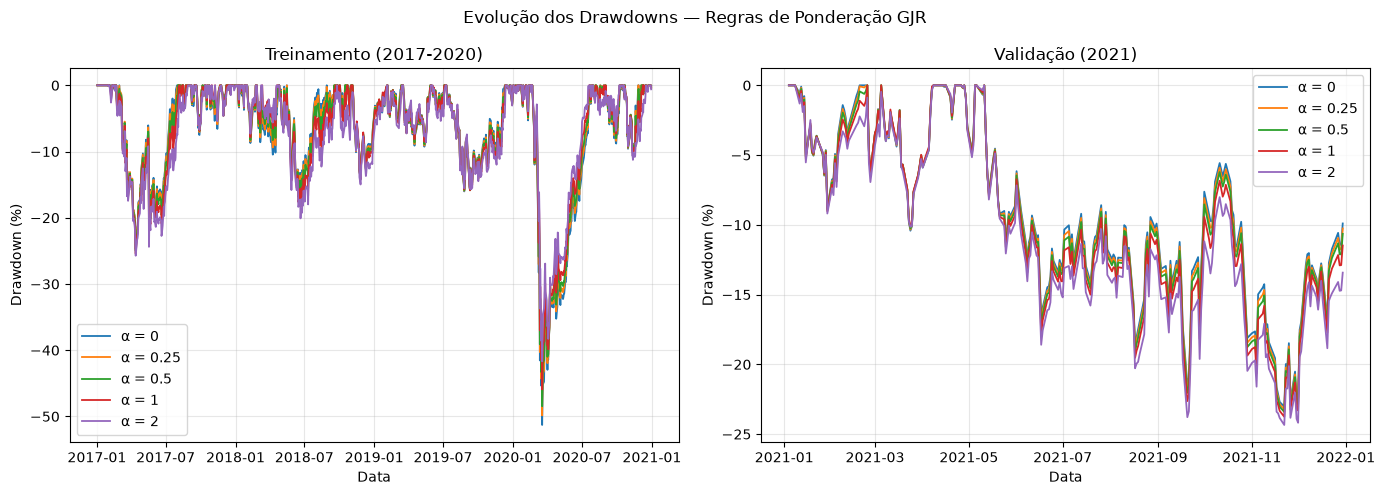

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (periodo, (inicio, fim)) in zip(axes, periodos.items()):

    for alpha, resultado in resultados_alpha.items():

        # Retornos líquidos do período
        r = aplicar_custos(
            resultado.loc[inicio:fim],
            custo=0.001
        )

        # Patrimônio acumulado
        patrimonio = (1 + r).cumprod()

        # Drawdown em relação ao máximo histórico
        pico = patrimonio.cummax().clip(lower=1.0)
        drawdown = (patrimonio / pico - 1) * 100

        ax.plot(
            drawdown.index,
            drawdown,
            label=f"α = {alpha:g}",
            linewidth=1.3
        )

    ax.set_title(periodo)
    ax.set_ylabel("Drawdown (%)")
    ax.set_xlabel("Data")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Evolução dos Drawdowns — Regras de Ponderação GJR")
plt.tight_layout()
plt.show()